In [10]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold, KFold

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             r2_score, mean_absolute_error, mean_squared_error)

# **Read el data**

In [11]:
import os, glob

# works on Kaggle (attached dataset) and locally
paths = glob.glob('/kaggle/input/**/used_cars_dataset.csv', recursive=True) + ['/Users/pawn/Downloads/used_cars_dataset.csv']
df = pd.read_csv(next(p for p in paths if os.path.exists(p)))
df.head()

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


# **EDA**

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           3000 non-null   object 
 1   brand                3000 non-null   object 
 2   model                3000 non-null   object 
 3   year                 3000 non-null   int64  
 4   mileage_km           2822 non-null   float64
 5   transmission         2941 non-null   object 
 6   fuel_type            2940 non-null   object 
 7   engine_cc            2879 non-null   float64
 8   body_type            3000 non-null   object 
 9   color                2851 non-null   object 
 10  city                 2941 non-null   object 
 11  seller_type          2942 non-null   object 
 12  accident_history     3000 non-null   object 
 13  previous_owners      2881 non-null   float64
 14  condition_rating     2851 non-null   object 
 15  photos_count         2907 non-null   f

In [13]:
df.describe()

,year,mileage_km,engine_cc,previous_owners,photos_count,price_egp
count,3000.000000,2.822000e+03,2879.000000,2881.000000,2907.000000,3.000000e+03
mean,2018.174333,1.093424e+05,1654.430358,1.887886,10.543172,7.555841e+05
std,37.275449,2.707599e+05,526.287599,1.008779,8.393483,2.043534e+06
min,0.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000e+00
25%,2017.000000,5.020000e+04,1500.000000,1.000000,8.000000,3.300000e+05
50%,2020.000000,8.570000e+04,1600.000000,2.000000,10.000000,5.525000e+05
75%,2022.000000,1.339250e+05,1600.000000,2.000000,13.000000,9.400000e+05
max,2050.000000,9.999999e+06,20000.000000,6.000000,300.000000,1.000000e+08


In [14]:
df.describe(include='object')

,listing_id,brand,model,transmission,fuel_type,body_type,color,city,seller_type,accident_history,condition_rating,sold_within_30_days
count,3000,3000,3000,2941,2940,3000,2851,2941,2942,3000,2851,3000
unique,2940,53,14,4,3,2,7,27,4,4,4,2
top,CAR-50004,Hyundai,Corolla,Automatic,Petrol,Sedan,White,Cairo,Individual,No,Good,No
freq,2,489,405,1927,2004,2522,792,841,1958,2396,1435,1635


In [15]:
df.duplicated().sum()

np.int64(40)

In [16]:
df.isnull().sum()

listing_id               0
brand                    0
model                    0
year                     0
mileage_km             178
transmission            59
fuel_type               60
engine_cc              121
body_type                0
color                  149
city                    59
seller_type             58
accident_history         0
previous_owners        119
condition_rating       149
photos_count            93
price_egp                0
sold_within_30_days      0
dtype: int64

In [17]:
# the categorical columns are messy (different spellings of the same value)
for col in ['brand', 'transmission', 'fuel_type', 'city', 'seller_type', 'accident_history', 'condition_rating']:
    print(col, '->', df[col].nunique(), 'unique values')
    print(df[col].value_counts(dropna=False).head(15).to_dict())
    print()

brand -> 53 unique values
{'Hyundai': 489, 'Toyota': 376, 'Nissan': 291, 'Kia': 252, 'Chevrolet': 206, 'MG': 191, 'Renault': 184, 'Skoda': 165, 'Fiat': 156, 'Chery': 133, 'BMW': 130, 'Mercedes-Benz': 113, 'Mitsubishi': 99, 'hyundai': 18, 'toyota': 17}

transmission -> 4 unique values
{'Automatic': 1927, 'Manual': 772, 'Auto': 179, 'MT': 63, nan: 59}

fuel_type -> 3 unique values
{'Petrol': 2004, 'Diesel': 516, 'Hybrid': 420, nan: 60}

city -> 27 unique values
{'Cairo': 841, 'Giza': 507, 'Alexandria': 408, 'Banha': 193, 'Mansoura': 192, 'Tanta': 181, 'Port Said': 148, 'Assiut': 136, 'Suez': 133, nan: 59, 'CAIRO': 32, 'cairo': 30, 'GIZA': 23, 'ALEXANDRIA': 19, 'giza': 18}

seller_type -> 4 unique values
{'Individual': 1958, 'Dealer': 866, 'individual': 81, nan: 58, 'dealer': 37}

accident_history -> 4 unique values
{'No': 2396, 'Yes': 516, 'N': 70, 'Y': 18}

condition_rating -> 4 unique values
{'Good': 1435, 'Fair': 653, 'Excellent': 582, 'Poor': 181, nan: 149}



In [18]:
# impossible values hiding in the numeric columns
print('year       :', sorted(df['year'].unique())[:5], '...', sorted(df['year'].unique())[-5:])
print('mileage_km :', df['mileage_km'].min(), '->', df['mileage_km'].max())
print('engine_cc  :', df['engine_cc'].min(), '->', df['engine_cc'].max())
print('photos     :', df['photos_count'].min(), '->', df['photos_count'].max())
print('price_egp  :', df['price_egp'].min(), '->', df['price_egp'].max())

year       : [np.int64(0), np.int64(1899), np.int64(1900), np.int64(1970), np.int64(1985)] ... [np.int64(2025), np.int64(2026), np.int64(2031), np.int64(2035), np.int64(2050)]
mileage_km : 0.0 -> 9999999.0
engine_cc  : 0.0 -> 20000.0
photos     : 0.0 -> 300.0
price_egp  : 0 -> 99999999


# **Cleaning**

## Duplicates

In [19]:
df = df.drop_duplicates().reset_index(drop=True)
df['listing_id'].duplicated().sum()

np.int64(20)

In [20]:
# listing_id is only an identifier, it has no predictive value
df = df.drop('listing_id', axis=1)
df.shape

(2960, 17)

## Fix inconsistent text

In [21]:
# spaces / upper / lower case
for col in ['brand', 'transmission', 'fuel_type', 'color', 'city', 'seller_type', 'accident_history', 'condition_rating']:
    df[col] = df[col].str.strip().str.title()

df['brand'] = df['brand'].replace({'Mercedes': 'Mercedes-Benz', 'Mg': 'MG', 'Bmw': 'BMW'})
df['transmission'] = df['transmission'].replace({'Auto': 'Automatic', 'Mt': 'Manual'})
df['accident_history'] = df['accident_history'].replace({'Y': 'Yes', 'N': 'No'})

for col in ['brand', 'transmission', 'city', 'seller_type', 'accident_history']:
    print(df[col].value_counts(dropna=False).to_dict())

{'Hyundai': 520, 'Toyota': 404, 'Nissan': 312, 'Kia': 262, 'Chevrolet': 220, 'MG': 198, 'Renault': 190, 'Skoda': 176, 'Fiat': 163, 'Chery': 146, 'BMW': 137, 'Mercedes-Benz': 125, 'Mitsubishi': 107}
{'Automatic': 2076, 'Manual': 825, nan: 59}
{'Cairo': 888, 'Giza': 540, 'Alexandria': 432, 'Mansoura': 203, 'Banha': 199, 'Tanta': 193, 'Port Said': 155, 'Suez': 147, 'Assiut': 145, nan: 58}
{'Individual': 2005, 'Dealer': 897, nan: 58}
{'No': 2432, 'Yes': 528}


## Impossible values -> NaN (the imputer will fill them later)

In [22]:
df.describe()

,year,mileage_km,engine_cc,previous_owners,photos_count,price_egp
count,2952.000000,2776.000000,2832.000000,2843.000000,2867.000000,2.960000e+03
mean,2018.932249,98975.612392,1639.230226,1.887091,10.287757,7.559838e+05
std,4.446620,65084.376722,169.245757,1.009587,3.526473,2.056189e+06
min,2005.000000,0.000000,1400.000000,1.000000,0.000000,0.000000e+00
25%,2017.000000,50275.000000,1500.000000,1.000000,8.000000,3.290000e+05
50%,2020.000000,85550.000000,1600.000000,2.000000,10.000000,5.525000e+05
75%,2022.000000,133125.000000,1600.000000,2.000000,13.000000,9.385000e+05
max,2026.000000,374600.000000,2000.000000,6.000000,23.000000,1.000000e+08


## Price (target) outliers

In [23]:
print(df['price_egp'].quantile([0, 0.001, 0.01, 0.5, 0.99, 0.999, 1]))

0.000    0.000000e+00
0.001    4.836000e+00
0.010    8.818000e+04
0.500    5.525000e+05
0.990    2.605000e+06
0.999    1.828700e+07
1.000    1.000000e+08
Name: price_egp, dtype: float64


In [24]:
# a price can not be filled, so rows with a fake price are dropped
df = df[df['price_egp'].between(20000, 10_000_000)].reset_index(drop=True)
df.shape

(2950, 17)

## Feature engineering

In [25]:
# age of the car is more useful than the raw year
df['car_age'] = 2026 - df['year']
df = df.drop('year', axis=1)
df.head()

,brand,model,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days,car_age
0,MG,ZS,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes,5.0
1,Kia,Cerato,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No,3.0
2,Skoda,Octavia,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No,17.0
3,Fiat,Tipo,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,Alexandria,Individual,No,2.0,Fair,7.0,319000,No,7.0
4,Mitsubishi,Lancer,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No,4.0


In [26]:
df.isnull().sum()

brand                    0
model                    0
mileage_km             181
transmission            59
fuel_type               59
engine_cc              128
body_type                0
color                  147
city                    58
seller_type             56
accident_history         0
previous_owners        117
condition_rating       148
photos_count            93
price_egp                0
sold_within_30_days      0
car_age                  8
dtype: int64

# **Visualization**

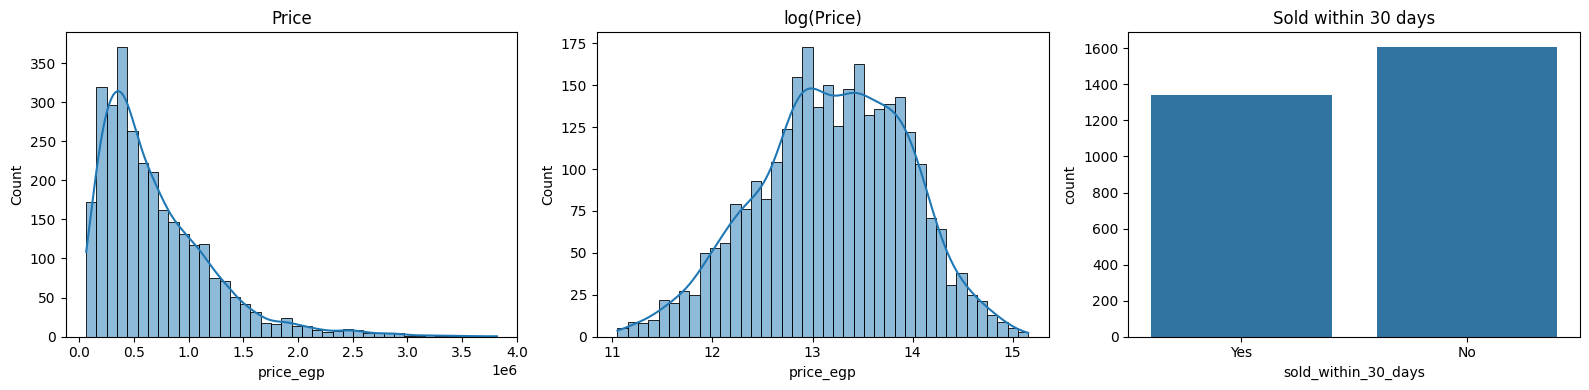

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['price_egp'], bins=40, kde=True, ax=axes[0]).set_title('Price')
sns.histplot(np.log1p(df['price_egp']), bins=40, kde=True, ax=axes[1]).set_title('log(Price)')
sns.countplot(x='sold_within_30_days', data=df, ax=axes[2]).set_title('Sold within 30 days')
plt.tight_layout()
plt.show()

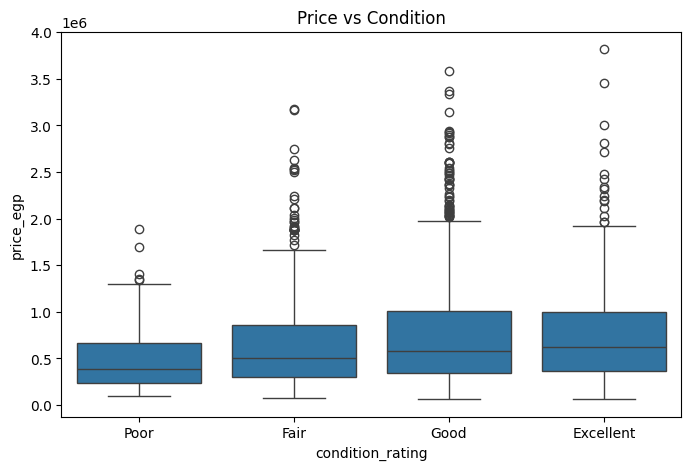

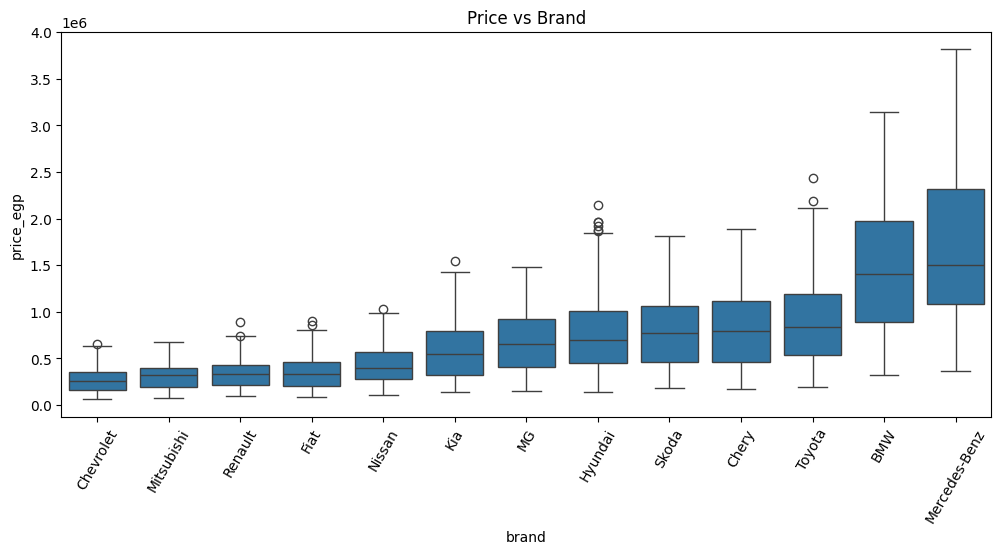

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='condition_rating', y='price_egp', data=df, order=['Poor', 'Fair', 'Good', 'Excellent'])
plt.title('Price vs Condition')
plt.show()

plt.figure(figsize=(12, 5))
order = df.groupby('brand')['price_egp'].median().sort_values().index
sns.boxplot(x='brand', y='price_egp', data=df, order=order)
plt.xticks(rotation=60)
plt.title('Price vs Brand')
plt.show()

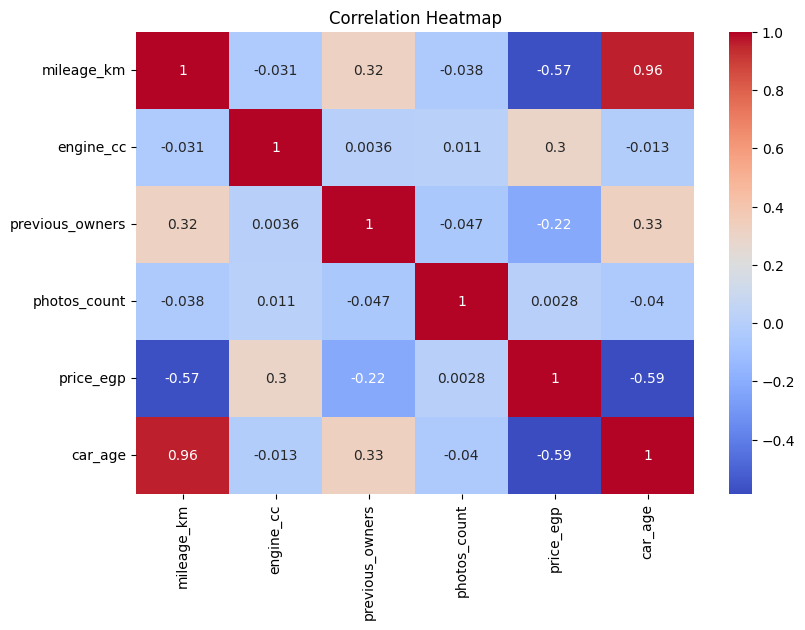

In [29]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# **Part 1: Classification  (predict `sold_within_30_days`)**

## Split

In [30]:
# sold_within_30_days -> 1 / 0
y_cls = df['sold_within_30_days'].map({'Yes': 1, 'No': 0})
X_cls = df.drop(['sold_within_30_days'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)
print(X_train.shape, X_test.shape)
y_train.value_counts(normalize=True)

(2360, 16) (590, 16)


sold_within_30_days
0    0.545339
1    0.454661
Name: proportion, dtype: float64

## Preprocessing  (impute + encode + scale, fitted on train only)

In [31]:
num_cols = ['mileage_km', 'engine_cc', 'previous_owners', 'photos_count', 'price_egp', 'car_age']
ord_cols = ['condition_rating']
cat_cols = ['brand', 'model', 'transmission', 'fuel_type', 'body_type', 'color', 'city', 'seller_type', 'accident_history']

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# condition has a real order so it gets ordinal encoding
ord_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['Poor', 'Fair', 'Good', 'Excellent']])),
    ('scaler', StandardScaler())
])

# nominal columns -> one hot (binary columns become a single 0/1 column)
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('ord', ord_pipe, ord_cols),
    ('cat', cat_pipe, cat_cols)
])

In [32]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(X_train_prep.shape, X_test_prep.shape)
print('NaN left:', np.isnan(X_train_prep).sum())

(2360, 57) (590, 57)
NaN left: 0


## Logistic Regression

In [33]:
results = []

def evaluate(name, model):
    y_pred = model.predict(X_test_prep)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })
    return y_pred

In [34]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_prep, y_train)

y_pred = evaluate('Logistic Regression', model)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.6423728813559322
              precision    recall  f1-score   support

           0       0.65      0.73      0.69       322
           1       0.62      0.53      0.58       268

    accuracy                           0.64       590
   macro avg       0.64      0.63      0.63       590
weighted avg       0.64      0.64      0.64       590



## KNN

In [35]:
model = KNeighborsClassifier(n_neighbors=7)
model.fit(X_train_prep, y_train)

y_pred = evaluate('KNN', model)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.5932203389830508
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       322
           1       0.56      0.49      0.52       268

    accuracy                           0.59       590
   macro avg       0.59      0.58      0.58       590
weighted avg       0.59      0.59      0.59       590



## Decision Tree

In [36]:
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
model.fit(X_train_prep, y_train)

y_pred_train = model.predict(X_train_prep)
y_pred = evaluate('Decision Tree', model)

print('Train accuracy:', accuracy_score(y_train, y_pred_train))
print('Test accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

Train accuracy: 0.6644067796610169
Test accuracy: 0.6220338983050847
              precision    recall  f1-score   support

           0       0.64      0.71      0.67       322
           1       0.60      0.51      0.55       268

    accuracy                           0.62       590
   macro avg       0.62      0.61      0.61       590
weighted avg       0.62      0.62      0.62       590

Confusion matrix:
[[230  92]
 [131 137]]


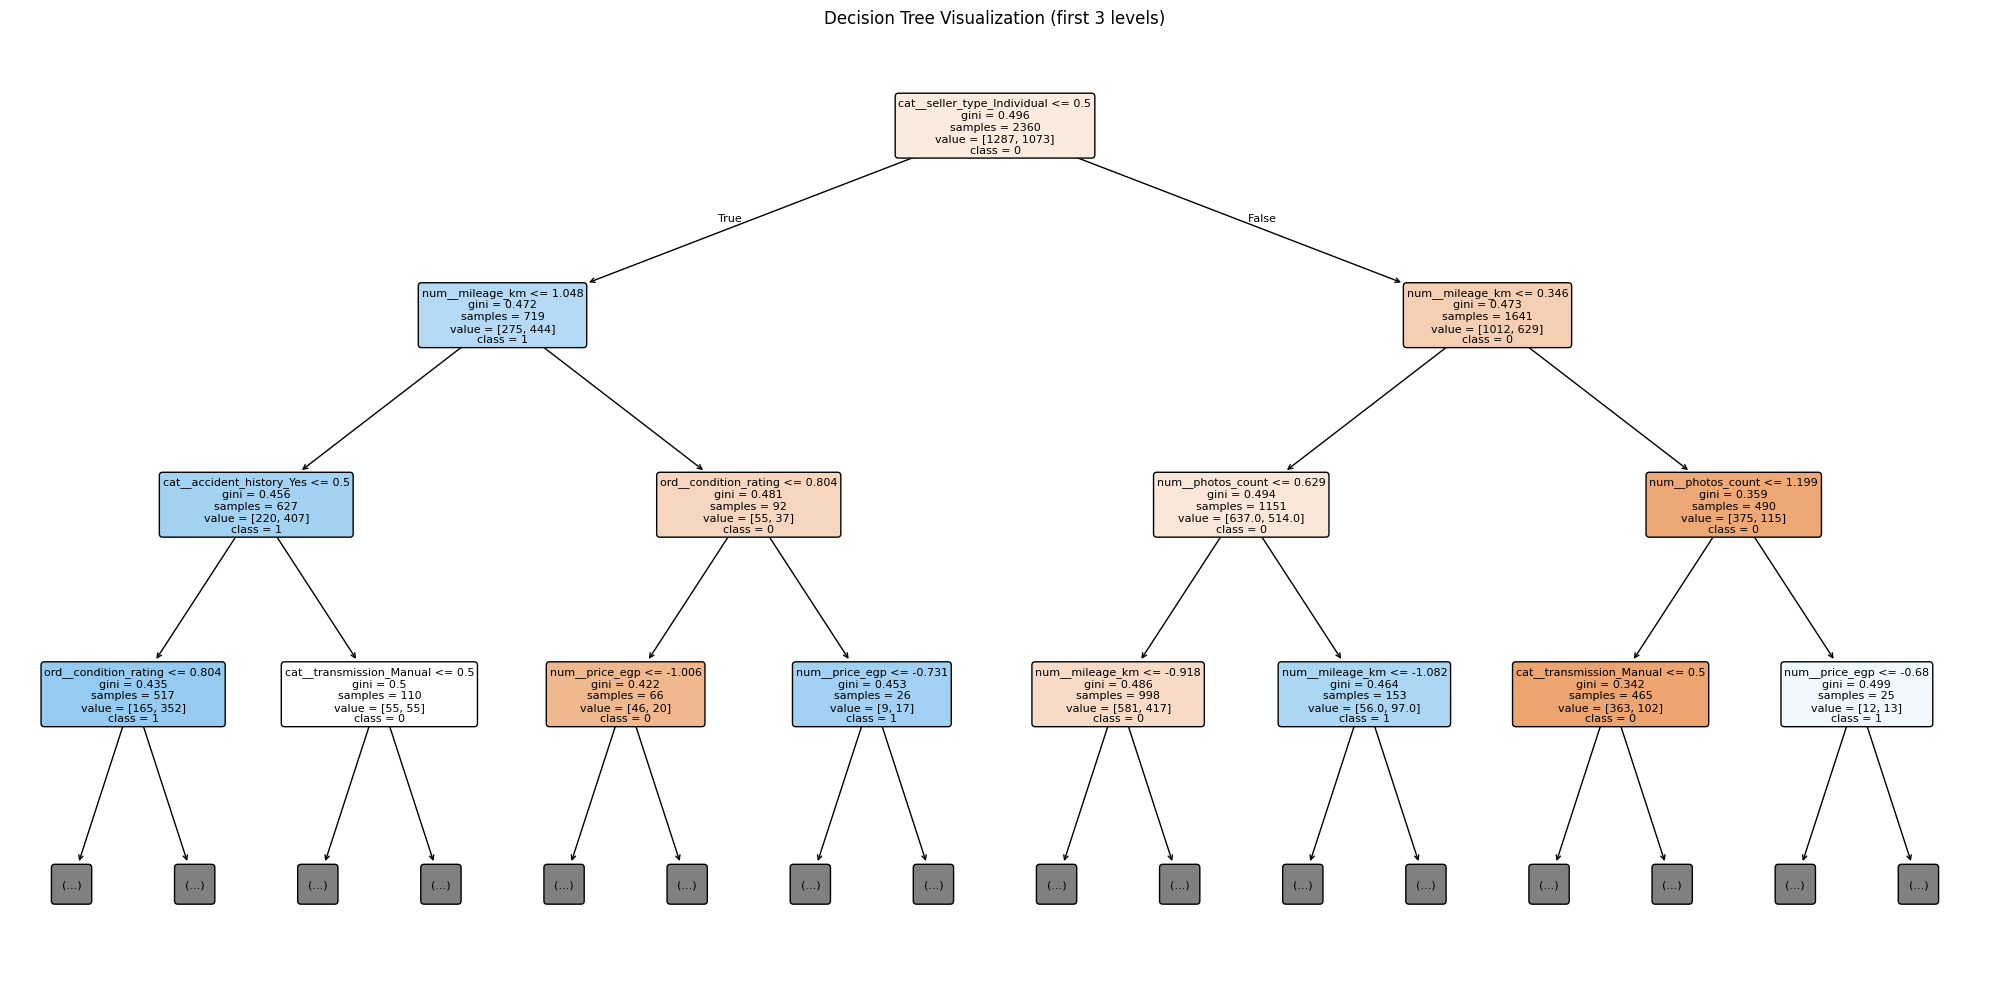

In [37]:
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=feature_names,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)
plt.title("Decision Tree Visualization (first 3 levels)")
plt.tight_layout()
plt.show()

## Random Forest

In [38]:
model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train_prep, y_train)

y_pred = evaluate('Random Forest', model)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.6237288135593221
              precision    recall  f1-score   support

           0       0.63      0.75      0.68       322
           1       0.61      0.47      0.53       268

    accuracy                           0.62       590
   macro avg       0.62      0.61      0.61       590
weighted avg       0.62      0.62      0.62       590



## SVC

In [39]:
model = SVC(C=0.1, kernel='linear', gamma='auto')
model.fit(X_train_prep, y_train)

y_pred = evaluate('SVC (linear)', model)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.6254237288135593
              precision    recall  f1-score   support

           0       0.63      0.78      0.69       322
           1       0.62      0.44      0.52       268

    accuracy                           0.63       590
   macro avg       0.63      0.61      0.61       590
weighted avg       0.63      0.63      0.61       590



# **Grid**

In [40]:
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [41]:
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='accuracy')
grid.fit(X_train_prep, y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': ['auto', 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']},
             scoring='accuracy')

In [42]:
print(grid.best_params_)
print(grid.best_score_)

{'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
0.660593220338983


In [43]:
best_model = grid.best_estimator_

y_pred = evaluate('SVC (Grid Search)', best_model)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.6728813559322034
              precision    recall  f1-score   support

           0       0.67      0.79      0.73       322
           1       0.68      0.53      0.60       268

    accuracy                           0.67       590
   macro avg       0.67      0.66      0.66       590
weighted avg       0.67      0.67      0.67       590



# **Random Search**

In [44]:
random_param = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [45]:
random = RandomizedSearchCV(estimator=SVC(), param_distributions=random_param, n_iter=10, cv=5, scoring='accuracy', random_state=42)
random.fit(X_train_prep, y_train)

print(random.best_params_)
print(random.best_score_)

{'kernel': 'rbf', 'gamma': 'auto', 'C': 10}
0.660593220338983


# **Cross Validation**

In [46]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

score = cross_val_score(best_model, X_train_prep, y_train, cv=kfold, scoring='accuracy')

print(score)
print(score.mean())

[0.66525424 0.62711864 0.68855932 0.63983051 0.65466102]
0.6550847457627118


# **Feature Selection**

In [47]:
f = SelectKBest(score_func=f_classif, k=10)
X_train_FS = f.fit_transform(X_train_prep, y_train)
X_test_FS = f.transform(X_test_prep)

print(X_train_FS.shape)
print('SelectKBest selected Features :', feature_names[f.get_support()].tolist())

(2360, 10)
SelectKBest selected Features : ['num__mileage_km', 'num__previous_owners', 'num__photos_count', 'num__price_egp', 'num__car_age', 'ord__condition_rating', 'cat__transmission_Manual', 'cat__fuel_type_Petrol', 'cat__seller_type_Individual', 'cat__accident_history_Yes']


Decision tree selected Features : ['num__mileage_km', 'cat__seller_type_Individual', 'num__price_egp', 'num__photos_count', 'ord__condition_rating']


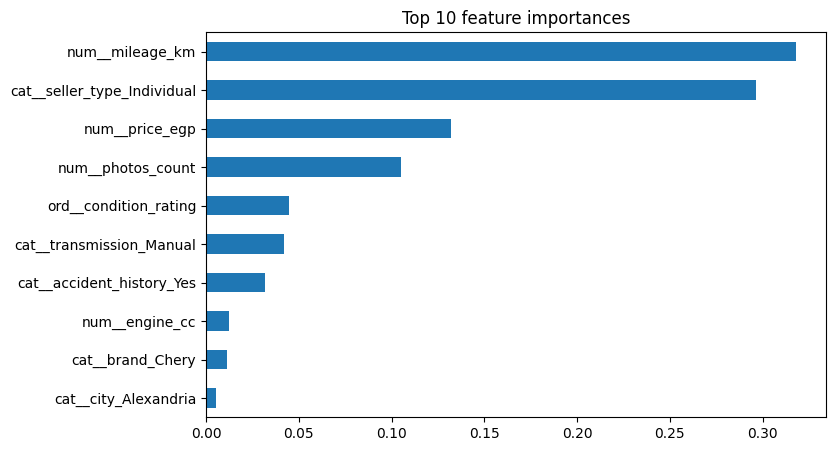

In [48]:
DT = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42)
DT.fit(X_train_prep, y_train)

importances = pd.Series(DT.feature_importances_, index=feature_names).sort_values(ascending=False)
print('Decision tree selected Features :', importances.index[:5].tolist())

importances.head(10).sort_values().plot(kind='barh', figsize=(8, 5), title='Top 10 feature importances')
plt.show()

In [49]:
# does the best model keep its accuracy with only the 10 selected features?
model_fs = SVC(**grid.best_params_)
model_fs.fit(X_train_FS, y_train)
print('All features     :', accuracy_score(y_test, best_model.predict(X_test_prep)))
print('10 best features :', accuracy_score(y_test, model_fs.predict(X_test_FS)))

All features     : 0.6728813559322034
10 best features : 0.6440677966101694


## Classification results

In [50]:
results_df = pd.DataFrame(results).set_index('Model').sort_values('Accuracy', ascending=False)
results_df

,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVC (Grid Search),0.672881,0.679426,0.529851,0.595388
Logistic Regression,0.642373,0.624454,0.533582,0.575453
SVC (linear),0.625424,0.624339,0.440299,0.516411
Random Forest,0.623729,0.610577,0.473881,0.533613
Decision Tree,0.622034,0.598253,0.511194,0.551308
KNN,0.593220,0.559829,0.488806,0.521912


# **Part 2: Regression  (predict `price_egp`)**

## Split

In [51]:
y_reg = np.log1p(df['price_egp'])   # price is right skewed so we train on log(price)
X_reg = df.drop(['price_egp', 'sold_within_30_days'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(2360, 15) (590, 15)


## Preprocessing

In [52]:
num_cols = ['mileage_km', 'engine_cc', 'previous_owners', 'photos_count', 'car_age']

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('ord', ord_pipe, ord_cols),
    ('cat', cat_pipe, cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(X_train_prep.shape, X_test_prep.shape)
print('NaN left:', np.isnan(X_train_prep).sum())

(2360, 56) (590, 56)
NaN left: 0


## Models

In [53]:
reg_results = []

def evaluate_reg(name, model):
    # metrics are reported in EGP (we undo the log)
    y_pred = np.expm1(model.predict(X_test_prep))
    y_true = np.expm1(y_test)
    reg_results.append({
        'Model': name,
        'R2': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))
    })
    return y_pred

In [54]:
model = LinearRegression()
model.fit(X_train_prep, y_train)

y_pred = evaluate_reg('Linear Regression', model)
reg_results[-1]

{'Model': 'Linear Regression',
 'R2': 0.9596360347247078,
 'MAE': 64749.172618021614,
 'RMSE': np.float64(102001.04320804012)}

In [55]:
model = DecisionTreeRegressor(max_depth=8, min_samples_split=10, min_samples_leaf=5, random_state=42)
model.fit(X_train_prep, y_train)

y_pred = evaluate_reg('Decision Tree', model)
reg_results[-1]

{'Model': 'Decision Tree',
 'R2': 0.8502142248598927,
 'MAE': 133986.9785808308,
 'RMSE': np.float64(196491.14671067672)}

In [56]:
model = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
model.fit(X_train_prep, y_train)

y_pred = evaluate_reg('Random Forest', model)
reg_results[-1]

{'Model': 'Random Forest',
 'R2': 0.9265662901431224,
 'MAE': 89281.29417735366,
 'RMSE': np.float64(137580.0415190391)}

In [57]:
model = SVR(C=1, kernel='rbf')
model.fit(X_train_prep, y_train)

y_pred = evaluate_reg('SVR', model)
reg_results[-1]

{'Model': 'SVR',
 'R2': 0.9315040602992686,
 'MAE': 72526.2057499078,
 'RMSE': np.float64(132874.03260415973)}

## SVR Grid Search

In [58]:
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['auto', 'scale']
}

grid = GridSearchCV(estimator=SVR(), param_grid=grid_params, cv=5, scoring='r2')
grid.fit(X_train_prep, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}
0.9730849872048829


In [59]:
best_reg = grid.best_estimator_

y_pred = evaluate_reg('SVR (Grid Search)', best_reg)
reg_results[-1]

{'Model': 'SVR (Grid Search)',
 'R2': 0.9588021801489568,
 'MAE': 62052.6339448705,
 'RMSE': np.float64(103049.24605063997)}

## Cross Validation

In [60]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

score = cross_val_score(best_reg, X_train_prep, y_train, cv=kfold, scoring='r2')

print(score)
print(score.mean())

[0.96809912 0.97842909 0.96981934 0.97486713 0.97387925]
0.9730187863968043


## Regression results

In [61]:
reg_results_df = pd.DataFrame(reg_results).set_index('Model').sort_values('R2', ascending=False)
reg_results_df

,R2,MAE,RMSE
Model,,,
Linear Regression,0.959636,64749.172618,102001.043208
SVR (Grid Search),0.958802,62052.633945,103049.246051
SVR,0.931504,72526.205750,132874.032604
Random Forest,0.926566,89281.294177,137580.041519
Decision Tree,0.850214,133986.978581,196491.146711


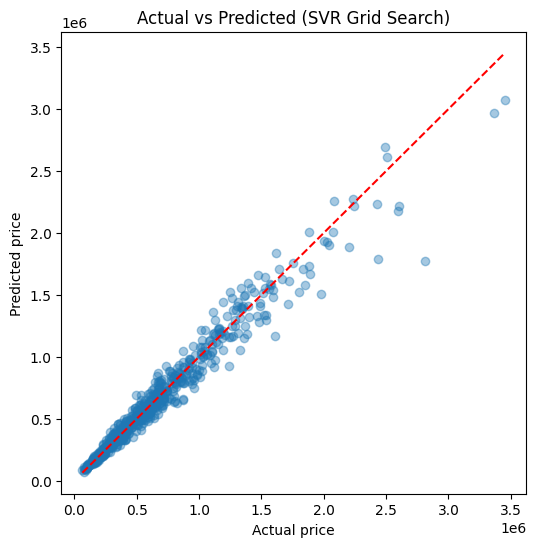

In [62]:
y_true = np.expm1(y_test)
y_pred = np.expm1(best_reg.predict(X_test_prep))

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.4)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual vs Predicted (SVR Grid Search)')
plt.show()